# 02 Descriptive statistics (survey 2025-2026)

Input: `data/processed/2025-2026_survey_clean.csv` (from notebook 01).
Output: tables in `results/`, charts in `plots/`.

All loss rates here are **hive-weighted**: total dead colonies / total colonies going into winter.
Chi-square tests treat every hive as independent, which they are not (hives in one apiary share
conditions), so their p-values are only a first look. The regression models in notebook 03 are the
real test.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_FILE = ROOT / "data" / "processed" / "2025-2026_survey_clean.csv"
RESULTS, PLOTS = ROOT / "results", ROOT / "plots"
RESULTS.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

HIVES_IN, HIVES_OUT = "2025_winter_in", "2026_winter_uit"
MIN_APIARIES = 20  # cells with fewer apiaries are greyed out

df = pd.read_csv(CLEAN_FILE)
print(f"{len(df)} apiaries, {df[HIVES_IN].sum():.0f} hives")

828 apiaries, 4843 hives


## Answer codes
Checked against row 2 of the raw survey export (1 = Nee for the three observation questions).

In [2]:
OBSERVATION = {1: "Not seen", 2: "A few", 3: "Moderate", 4: "Many", 5: "Don't know"}
LABELS = {
    "imker_methode": {1: "Controlled", 2: "Natural", 3: "Regulier", 4: "Unknown / mixed"},
    "winter_food": {1: "Sugar only", 2: "Honey + sugar", 3: "Honey only"},
    "varroa_treatment": {1: "Full 3-step", 2: "Alternative full", 3: "Winter only",
                         4: "Summer only", 5: "No treatment"},
    "varroa_observation": OBSERVATION,
    "aziatische_hoornaar": OBSERVATION,
    "deformed_wings": OBSERVATION,
}
NAMES = {
    "imker_methode": "beekeeping method", "winter_food": "winter feed",
    "varroa_treatment": "varroa treatment", "varroa_observation": "varroa seen",
    "aziatische_hoornaar": "Asian hornet seen", "deformed_wings": "deformed wings seen",
}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})

## 1. Overall winter loss

In [3]:
overall = pd.DataFrame([{
    "apiaries": len(df),
    "beekeepers": df["id_beekeeper"].nunique(),
    "hives_in": df[HIVES_IN].sum(),
    "hives_out": df[HIVES_OUT].sum(),
    "deaths": df["deaths"].sum(),
}])
overall["loss_pct"] = (100 * overall["deaths"] / overall["hives_in"]).round(2)
overall.to_csv(RESULTS / "02_overall.csv", index=False)
OVERALL_PCT = overall.loc[0, "loss_pct"]
overall

,apiaries,beekeepers,hives_in,hives_out,deaths,loss_pct
0,828,692,4843.0,3796.0,1047.0,21.62


## 2. Loss by each survey question

In [4]:
def loss_by_group(data, col):
    """Hive-weighted loss per answer. Apiaries that skipped the question are left out."""
    t = (data.dropna(subset=[col])
             .groupby(col)
             .agg(apiaries=("id_location", "size"), hives_in=(HIVES_IN, "sum"), deaths=("deaths", "sum")))
    t.index = t.index.astype(int)
    t.insert(0, "answer", t.index.map(LABELS[col]))
    t["share_of_apiaries_pct"] = (100 * t["apiaries"] / t["apiaries"].sum()).round(1)
    t["loss_pct"] = (100 * t["deaths"] / t["hives_in"]).round(2)
    return t


def chi_square(data, col):
    """Global test, then Bonferroni-corrected pairwise tests if the global one is significant."""
    table = data.dropna(subset=[col]).groupby(col)[[HIVES_OUT, "deaths"]].sum()
    table.index = table.index.astype(int)
    _, p_global, _, _ = chi2_contingency(table)
    pairs = []
    if p_global < 0.05:
        combos = list(combinations(table.index, 2))
        for a, b in combos:
            _, p, _, _ = chi2_contingency(table.loc[[a, b]])
            pairs.append({"group_a": LABELS[col][a], "group_b": LABELS[col][b], "p_value": p,
                          "significant_bonferroni": p < 0.05 / len(combos)})
    return p_global, pd.DataFrame(pairs)


def plot_loss(t, col):
    t = t.sort_values("loss_pct")
    fig, ax = plt.subplots(figsize=(7.5, 0.55 * len(t) + 1.4))
    ax.barh(t["answer"], t["loss_pct"], color="#2c6b8e", height=0.6)
    ax.axvline(OVERALL_PCT, color="#7b8794", ls="--", lw=1)
    ax.text(OVERALL_PCT, -0.75, f" all apiaries {OVERALL_PCT:.1f}%", color="#7b8794", fontsize=9, va="center")
    ax.set_ylim(-1, len(t) - 0.5)
    for i, (_, r) in enumerate(t.iterrows()):
        ax.text(r["loss_pct"] + 0.4, i, f"{r['loss_pct']:.1f}%   (n = {r['apiaries']} apiaries, {r['hives_in']:,.0f} hives)",
                va="center", fontsize=9)
    ax.set_xlim(0, t["loss_pct"].max() * 1.6)
    ax.set_xlabel("Winter loss (% of colonies, hive-weighted)")
    ax.set_title(f"Winter loss by {NAMES[col]}")
    fig.savefig(PLOTS / f"02_loss_by_{col}.png")
    plt.show()

=== BEEKEEPING METHOD   (chi-square p = 0.0000)


,answer,apiaries,hives_in,deaths,share_of_apiaries_pct,loss_pct
imker_methode,,,,,,
1,Controlled,86,749.0,102.0,10.4,13.62
2,Natural,96,435.0,117.0,11.6,26.90
3,Regulier,458,2621.0,601.0,55.4,22.93
4,Unknown / mixed,187,1037.0,227.0,22.6,21.89


,group_a,group_b,p_value,significant_bonferroni
0,Controlled,Natural,0.00000,True
1,Controlled,Regulier,0.00000,True
2,Controlled,Unknown / mixed,0.00001,True
3,Natural,Regulier,0.08082,False
4,Natural,Unknown / mixed,0.04512,False
5,Regulier,Unknown / mixed,0.52629,False


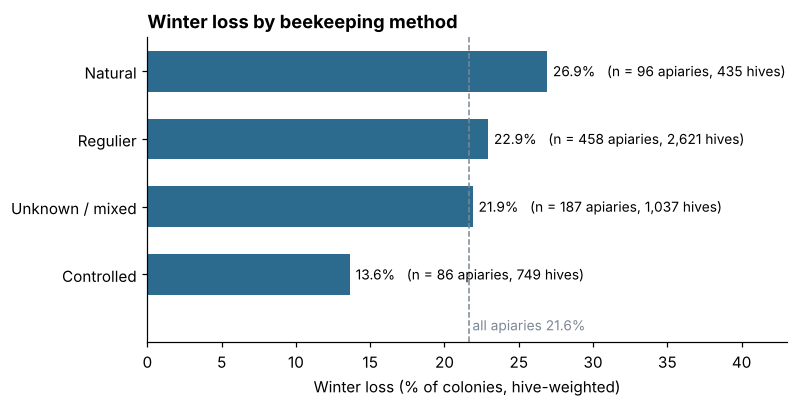

=== WINTER FEED   (chi-square p = 0.0000)


,answer,apiaries,hives_in,deaths,share_of_apiaries_pct,loss_pct
winter_food,,,,,,
1,Sugar only,178,1123.0,228.0,21.5,20.30
2,Honey + sugar,538,3274.0,638.0,65.1,19.49
3,Honey only,110,442.0,179.0,13.3,40.50


,group_a,group_b,p_value,significant_bonferroni
0,Sugar only,Honey + sugar,0.58248,False
1,Sugar only,Honey only,0.00000,True
2,Honey + sugar,Honey only,0.00000,True


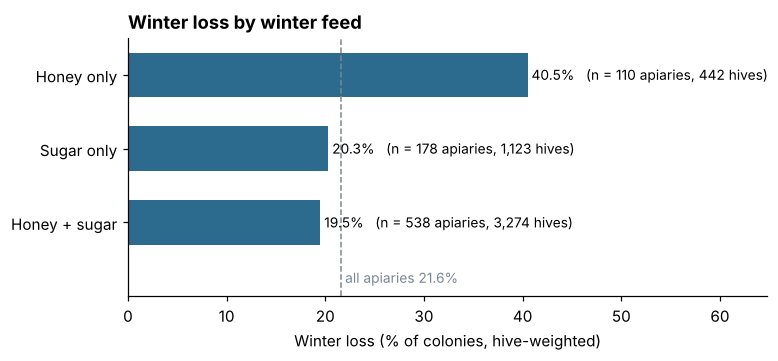

=== VARROA TREATMENT   (chi-square p = 0.0000)


,answer,apiaries,hives_in,deaths,share_of_apiaries_pct,loss_pct
varroa_treatment,,,,,,
1,Full 3-step,402,2407.0,461.0,48.6,19.15
2,Alternative full,79,618.0,83.0,9.5,13.43
3,Winter only,88,428.0,136.0,10.6,31.78
4,Summer only,117,623.0,177.0,14.1,28.41
5,No treatment,142,767.0,190.0,17.1,24.77


,group_a,group_b,p_value,significant_bonferroni
0,Full 3-step,Alternative full,0.00117,True
1,Full 3-step,Winter only,0.00000,True
2,Full 3-step,Summer only,0.00000,True
3,Full 3-step,No treatment,0.00095,True
4,Alternative full,Winter only,0.00000,True
5,Alternative full,Summer only,0.00000,True
6,Alternative full,No treatment,0.00000,True
7,Winter only,Summer only,0.26988,False
8,Winter only,No treatment,0.01113,False
9,Summer only,No treatment,0.14171,False


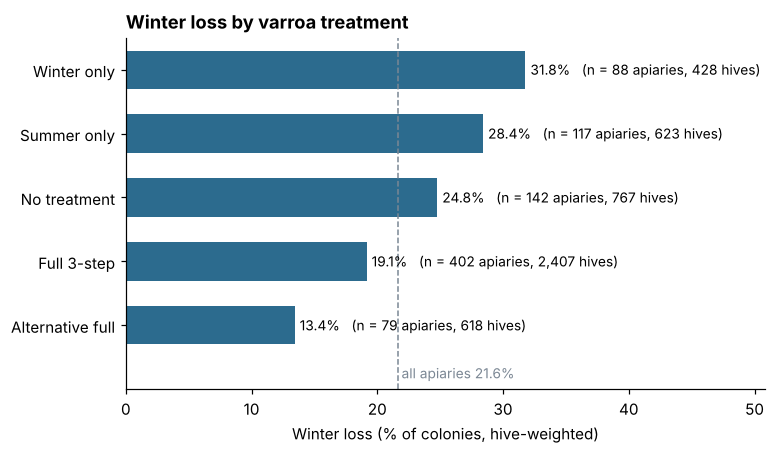

=== VARROA SEEN   (chi-square p = 0.0000)


,answer,apiaries,hives_in,deaths,share_of_apiaries_pct,loss_pct
varroa_observation,,,,,,
1,Not seen,100,301.0,94.0,12.1,31.23
2,A few,252,1626.0,352.0,30.4,21.65
3,Moderate,340,2168.0,422.0,41.1,19.46
4,Many,73,473.0,106.0,8.8,22.41
5,Don't know,63,275.0,73.0,7.6,26.55


,group_a,group_b,p_value,significant_bonferroni
0,Not seen,A few,0.00039,True
1,Not seen,Moderate,0.00000,True
2,Not seen,Many,0.00809,False
3,Not seen,Don't know,0.25198,False
4,A few,Moderate,0.10723,False
5,A few,Many,0.77191,False
6,A few,Don't know,0.08462,False
7,Moderate,Many,0.16525,False
8,Moderate,Don't know,0.00754,False
9,Many,Don't know,0.23434,False


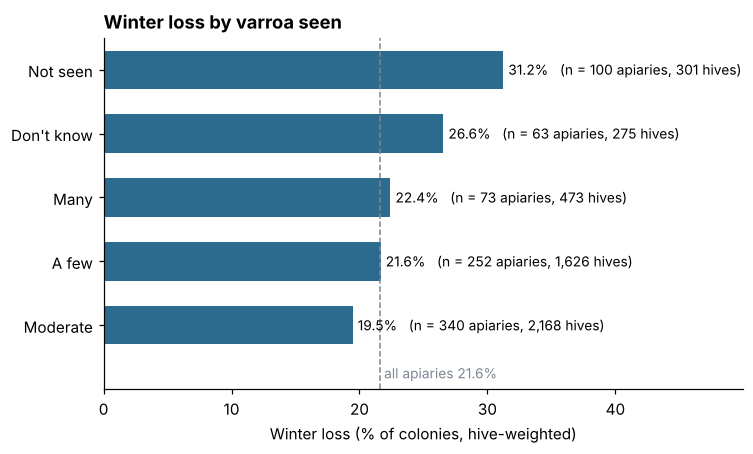

=== ASIAN HORNET SEEN   (chi-square p = 0.0000)


,answer,apiaries,hives_in,deaths,share_of_apiaries_pct,loss_pct
aziatische_hoornaar,,,,,,
1,Not seen,336,1708.0,443.0,40.6,25.94
2,A few,187,976.0,198.0,22.6,20.29
3,Moderate,150,1002.0,183.0,18.1,18.26
4,Many,138,1100.0,206.0,16.7,18.73
5,Don't know,17,57.0,17.0,2.1,29.82


,group_a,group_b,p_value,significant_bonferroni
0,Not seen,A few,0.00113,True
1,Not seen,Moderate,0.00001,True
2,Not seen,Many,0.00001,True
3,Not seen,Don't know,0.61398,False
4,A few,Moderate,0.27843,False
5,A few,Many,0.40072,False
6,A few,Don't know,0.11965,False
7,Moderate,Many,0.82801,False
8,Moderate,Don't know,0.04601,False
9,Many,Don't know,0.05758,False


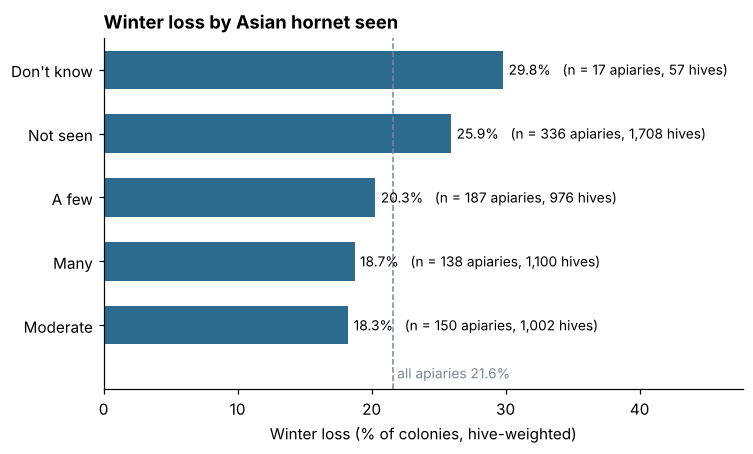

=== DEFORMED WINGS SEEN   (chi-square p = 0.9238)


,answer,apiaries,hives_in,deaths,share_of_apiaries_pct,loss_pct
deformed_wings,,,,,,
1,Not seen,652,3552.0,774.0,78.7,21.79
2,A few,91,751.0,159.0,11.0,21.17
3,Moderate,20,176.0,39.0,2.4,22.16
4,Many,1,2.0,0.0,0.1,0.00
5,Don't know,64,362.0,75.0,7.7,20.72


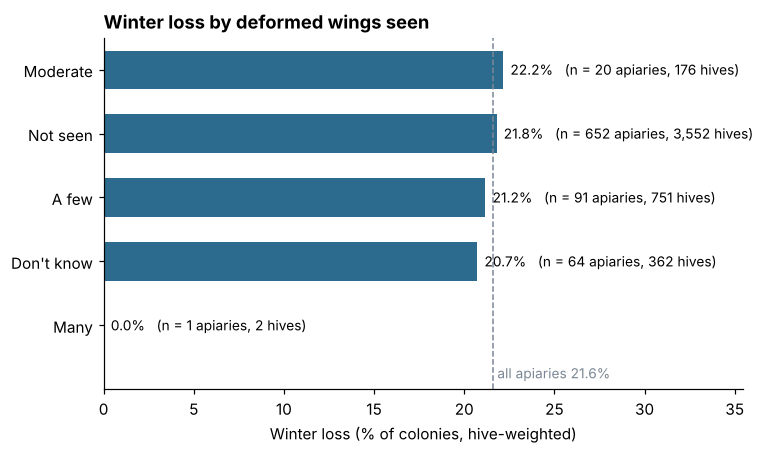

In [5]:
tests = []
for col in LABELS:
    t = loss_by_group(df, col)
    t.to_csv(RESULTS / f"02_loss_by_{col}.csv")
    p_global, pairs = chi_square(df, col)
    tests.append({"variable": col, "p_global": p_global})

    print(f"=== {NAMES[col].upper()}   (chi-square p = {p_global:.4f})")
    display(t)
    if len(pairs):
        pairs.to_csv(RESULTS / f"02_pairwise_{col}.csv", index=False)
        display(pairs.round(5))
    plot_loss(t, col)

pd.DataFrame(tests).to_csv(RESULTS / "02_chi_square.csv", index=False)

## 3. Varroa treatment x winter feed
Each cell: hive-weighted loss and the number of apiaries. Cells with fewer than 20 apiaries are greyed out:
their rate is too unstable to draw conclusions from.

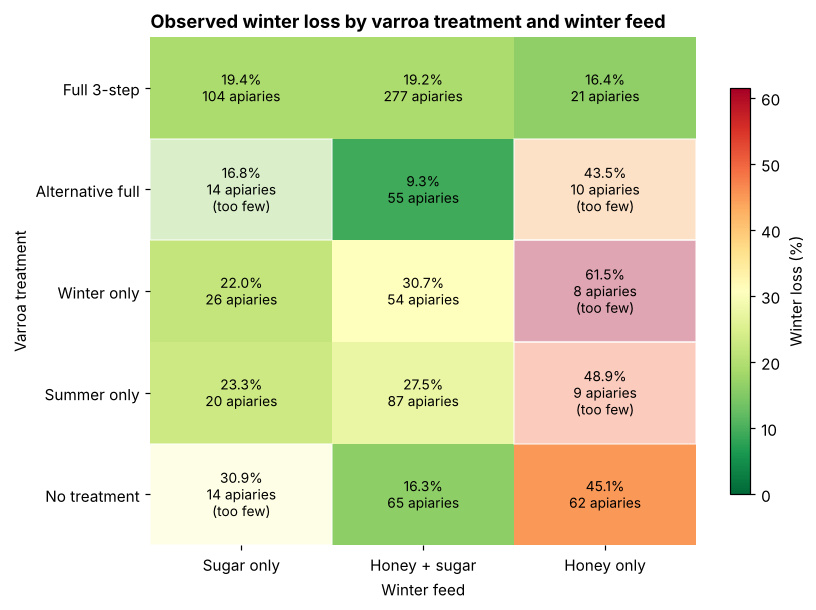

In [6]:
cells = (df.dropna(subset=["varroa_treatment", "winter_food"])
            .groupby(["varroa_treatment", "winter_food"])
            .agg(apiaries=("id_location", "size"), hives_in=(HIVES_IN, "sum"), deaths=("deaths", "sum"))
            .reset_index())
cells["loss_pct"] = (100 * cells["deaths"] / cells["hives_in"]).round(2)
cells.to_csv(RESULTS / "02_loss_treatment_x_feed.csv", index=False)

grid = cells.pivot(index="varroa_treatment", columns="winter_food", values="loss_pct")
n = cells.pivot(index="varroa_treatment", columns="winter_food", values="apiaries")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(grid.to_numpy(float), cmap="RdYlGn_r", vmin=0, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v, k = grid.iat[i, j], n.iat[i, j]
        if pd.isna(v):
            continue
        small = k < MIN_APIARIES
        if small:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color="white", alpha=0.65))
        ax.text(j, i, f"{v:.1f}%\n{int(k)} apiaries" + ("\n(too few)" if small else ""),
                ha="center", va="center", fontsize=9)
ax.set_xticks(range(grid.shape[1]), [LABELS["winter_food"][x] for x in grid.columns])
ax.set_yticks(range(grid.shape[0]), [LABELS["varroa_treatment"][x] for x in grid.index])
ax.set_xlabel("Winter feed")
ax.set_ylabel("Varroa treatment")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label="Winter loss (%)", shrink=0.8)
ax.set_title("Observed winter loss by varroa treatment and winter feed")
fig.savefig(PLOTS / "02_heatmap_treatment_x_feed.png")
plt.show()

## 4. How practices differ by beekeeping method
Share of apiaries (%) within each method. If one method feeds honey or skips treatment more often,
part of its higher loss comes from those practices, not from the method itself. Notebook 03 separates the two.

In [7]:
for other in ["winter_food", "varroa_treatment"]:
    d = df.dropna(subset=["imker_methode", other])
    share = pd.crosstab(d["imker_methode"].astype(int), d[other].astype(int), normalize="index") * 100
    share.index = share.index.map(LABELS["imker_methode"])
    share.columns = share.columns.map(LABELS[other])
    share = share.round(1)
    share.to_csv(RESULTS / f"02_method_x_{other}_share.csv")
    print(f"Share of apiaries by {NAMES[other]} (%)")
    display(share)

Share of apiaries by winter feed (%)


winter_food,Sugar only,Honey + sugar,Honey only
imker_methode,,,
Controlled,27.9,68.6,3.5
Natural,6.4,36.2,57.4
Regulier,24.9,69.0,6.1
Unknown / mixed,18.2,69.0,12.8


Share of apiaries by varroa treatment (%)


varroa_treatment,Full 3-step,Alternative full,Winter only,Summer only,No treatment
imker_methode,,,,,
Controlled,58.1,14.0,5.8,16.3,5.8
Natural,9.4,10.4,5.2,5.2,69.8
Regulier,57.4,7.0,12.2,15.1,8.3
Unknown / mixed,42.8,13.4,11.8,15.5,16.6
